##  Setup
Import libraries and fix the random seed for reproducibility.

In [43]:
# Install the UCI loader if it is not available (needs internet access)
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    %pip install ucimlrepo
    from ucimlrepo import fetch_ucirepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 3. Load the data
Downloaded directly from UCI so the notebook is self-contained. Columns are renamed to short, safe names (by position).

In [44]:
data = fetch_ucirepo(id=165)
X = data.data.features.copy()
y = data.data.targets.iloc[:, 0].copy()

X.columns = ["Cement", "Slag", "FlyAsh", "Water", "Superplasticizer",
             "CoarseAgg", "FineAgg", "Age"]
y.name = "Strength"

df = pd.concat([X, y], axis=1)
print("Shape:", df.shape)
df.head()

Shape: (1030, 9)


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAgg,FineAgg,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


Units: ingredients are in kg per m³ of mixture, `Age` is in days, and `Strength` (target) is compressive strength in MPa.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Data structure and quality

In [45]:
info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                     "non_null": df.notnull().sum(),
                     "missing": df.isnull().sum(),
                     "unique": df.nunique()})
info

,dtype,non_null,missing,unique
Cement,float64,1030,0,278
Slag,float64,1030,0,185
FlyAsh,float64,1030,0,156
Water,float64,1030,0,195
Superplasticizer,float64,1030,0,111
CoarseAgg,float64,1030,0,284
FineAgg,float64,1030,0,302
Age,int64,1030,0,14
Strength,float64,1030,0,845


In [46]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 25
Shape after removing duplicates: (1005, 9)


### 4.2 Summary statistics

In [47]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Cement,1005.0,278.63,104.34,102.00,190.70,265.0,349.00,540.0
Slag,1005.0,72.04,86.17,0.00,0.00,20.0,142.50,359.4
FlyAsh,1005.0,55.54,64.21,0.00,0.00,0.0,118.30,200.1
Water,1005.0,182.08,21.34,121.80,166.60,185.7,192.90,247.0
Superplasticizer,1005.0,6.03,5.92,0.00,0.00,6.1,10.00,32.2
CoarseAgg,1005.0,974.38,77.58,801.00,932.00,968.0,1031.00,1145.0
FineAgg,1005.0,772.69,80.34,594.00,724.30,780.0,822.20,992.6
Age,1005.0,45.86,63.73,1.00,7.00,28.0,56.00,365.0
Strength,1005.0,35.25,16.28,2.33,23.52,33.8,44.87,82.6


### 4.3 Target distribution (Chart 1)

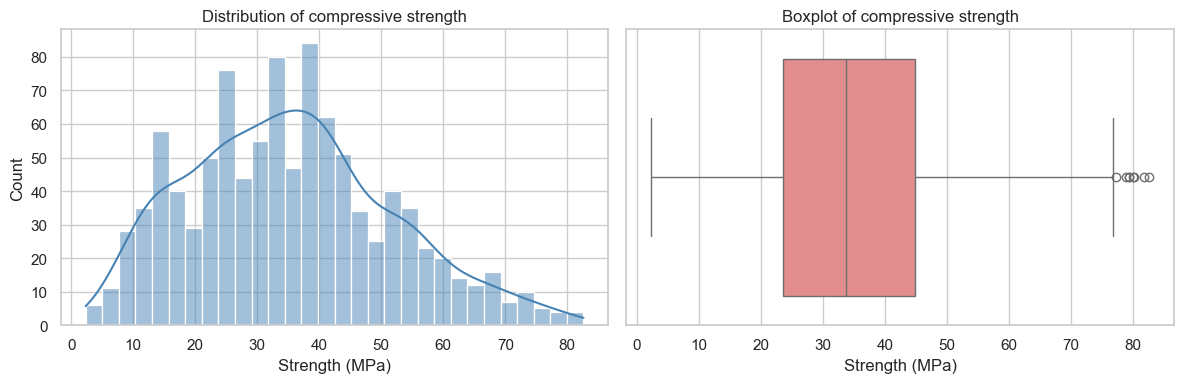

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Strength"], bins=30, kde=True, color="steelblue", ax=ax[0])
ax[0].set_title("Distribution of compressive strength")
ax[0].set_xlabel("Strength (MPa)")
sns.boxplot(x=df["Strength"], color="lightcoral", ax=ax[1])
ax[1].set_title("Boxplot of compressive strength")
ax[1].set_xlabel("Strength (MPa)")
plt.tight_layout()
plt.show()

### 4.4 Feature distributions (Chart 2)

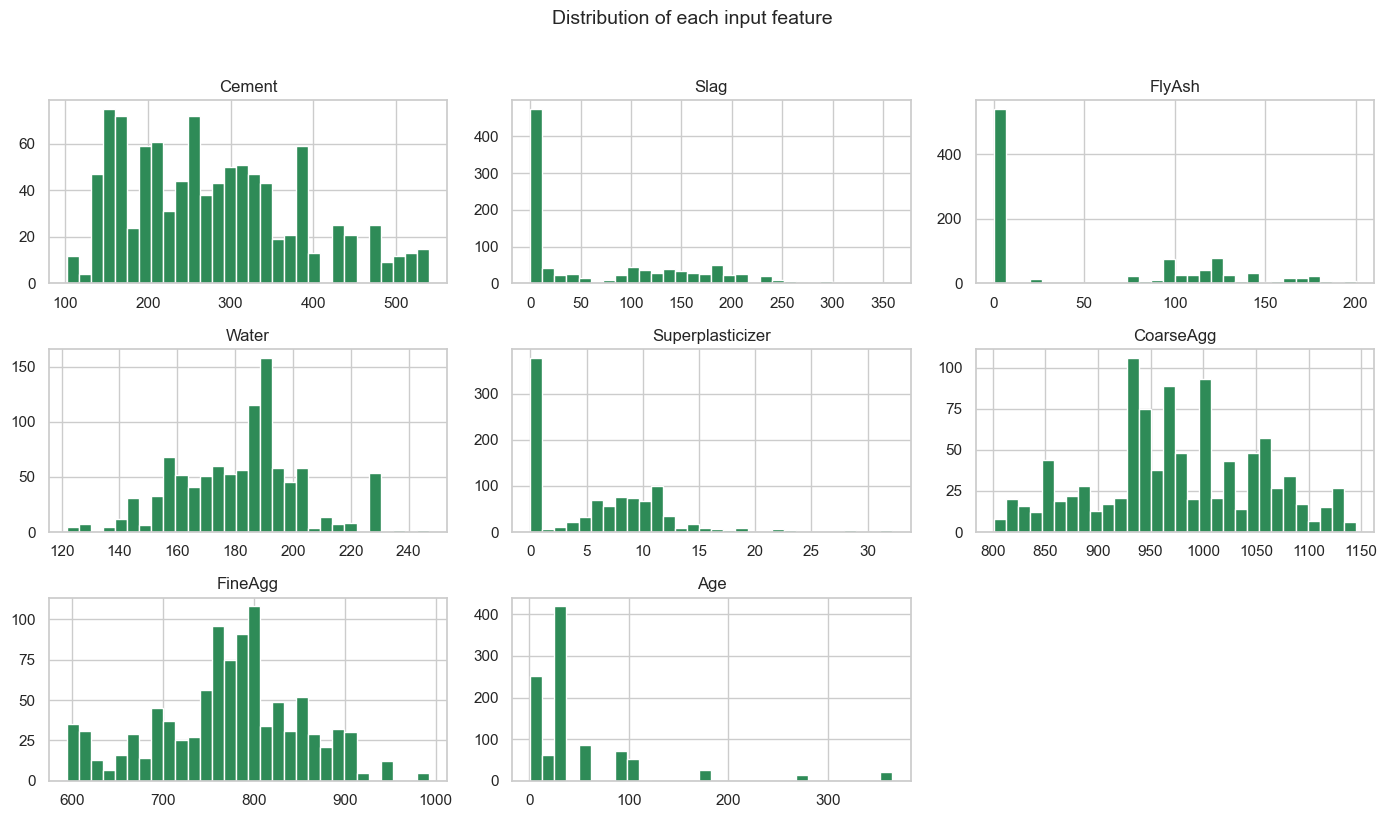

In [49]:
features = X.columns.tolist()
df[features].hist(bins=30, figsize=(14, 8), color="seagreen", edgecolor="white")
plt.suptitle("Distribution of each input feature", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Several ingredients (`Slag`, `FlyAsh`, `Superplasticizer`) have many zeros because not every mix uses them. `Age` is highly skewed: most samples are tested at 3, 7, 28 or 90 days.

In [50]:
print("Share of zero values per feature (%):")
(df[features].eq(0).mean() * 100).round(1).to_frame("zero_%").T

Share of zero values per feature (%):


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAgg,FineAgg,Age
zero_%,0.0,46.8,53.8,0.0,37.6,0.0,0.0,0.0


### 4.5 Correlation analysis (Chart 3)

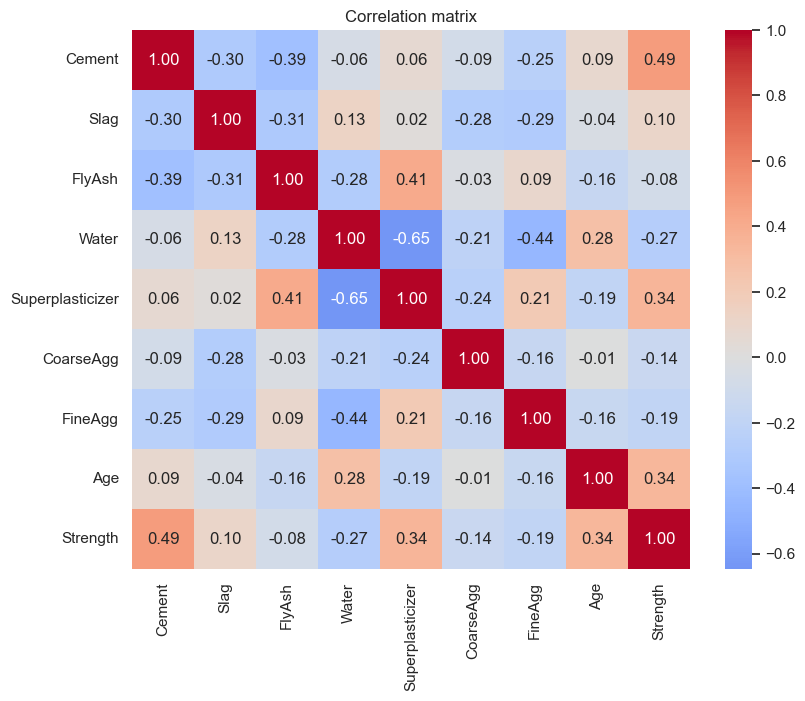

In [51]:
corr = df.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

In [52]:
corr["Strength"].drop("Strength").sort_values(ascending=False).round(3).to_frame("corr with Strength")

,corr with Strength
Cement,0.488
Superplasticizer,0.344
Age,0.337
Slag,0.103
FlyAsh,-0.081
CoarseAgg,-0.145
FineAgg,-0.186
Water,-0.270


### 4.6 Relationship between key features and strength (Chart 4)

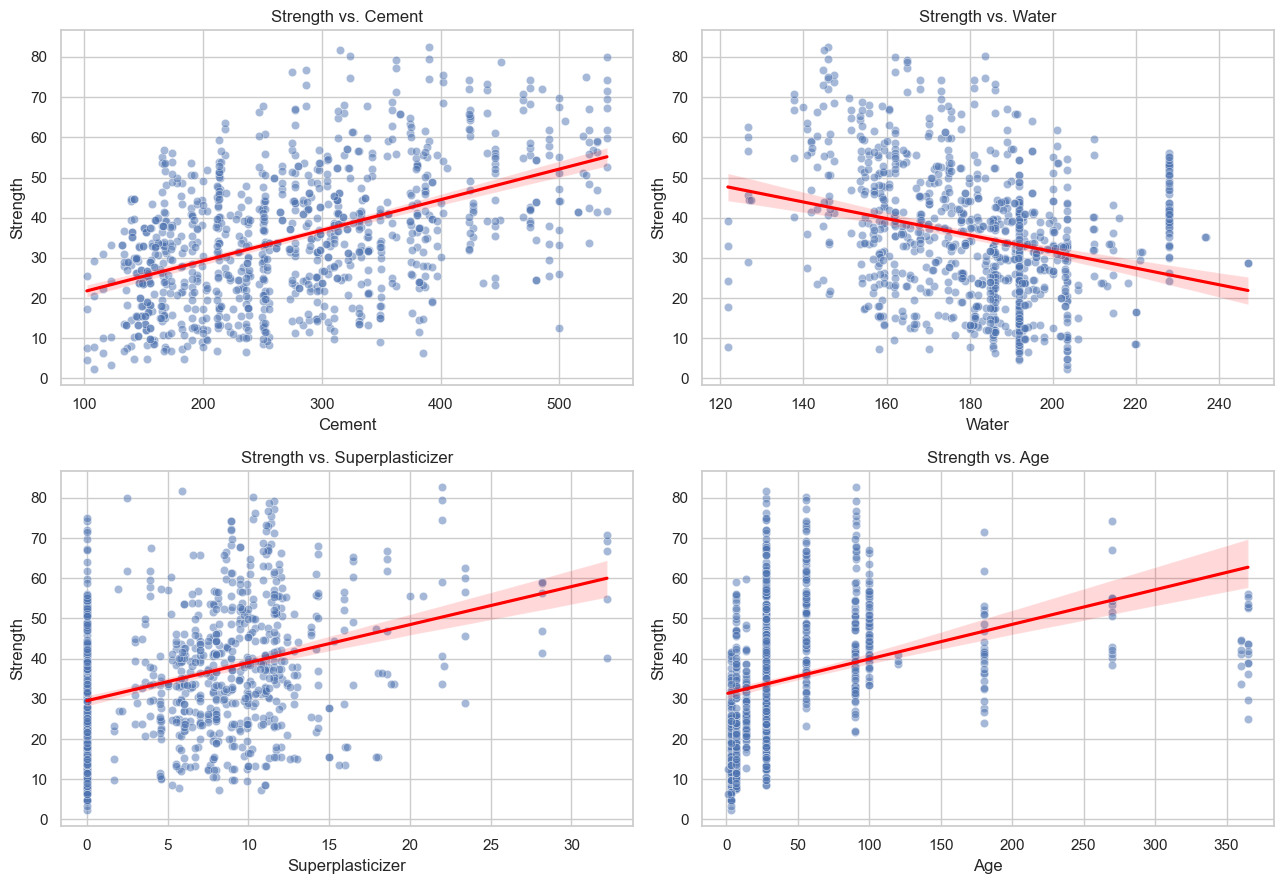

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ["Cement", "Water", "Superplasticizer", "Age"]):
    sns.scatterplot(data=df, x=col, y="Strength", alpha=0.5, ax=ax)
    sns.regplot(data=df, x=col, y="Strength", scatter=False, color="red", ax=ax)
    ax.set_title(f"Strength vs. {col}")
plt.tight_layout()
plt.show()

### 4.7 Effect of curing age (Chart 5)

,count,mean,std
AgeGroup,,,
1-7 d,253,21.59,12.37
8-28 d,481,35.44,14.03
29-56 d,86,50.72,13.75
57+ d,185,46.25,12.11


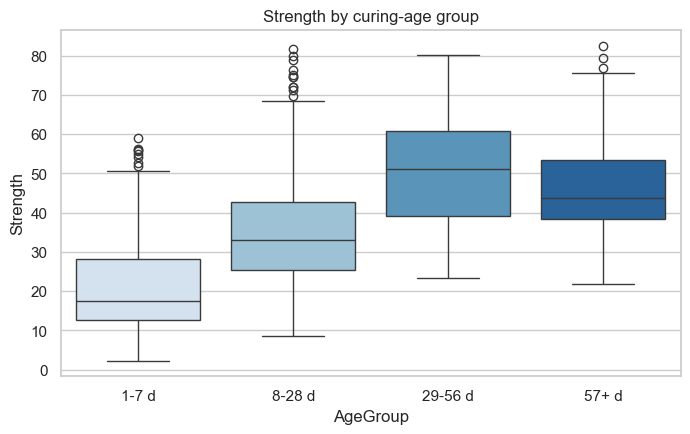

In [54]:
age_table = (df.assign(AgeGroup=pd.cut(df["Age"], [0, 7, 28, 56, 400],
                                       labels=["1-7 d", "8-28 d", "29-56 d", "57+ d"]))
               .groupby("AgeGroup", observed=True)["Strength"]
               .agg(["count", "mean", "std"]).round(2))
display(age_table)

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df.assign(AgeGroup=pd.cut(df["Age"], [0, 7, 28, 56, 400],
                                           labels=["1-7 d", "8-28 d", "29-56 d", "57+ d"])),
            x="AgeGroup", y="Strength", hue="AgeGroup", palette="Blues", legend=False)
plt.title("Strength by curing-age group")
plt.show()

### 4.8 Pairwise view of the most related features (Chart 6)

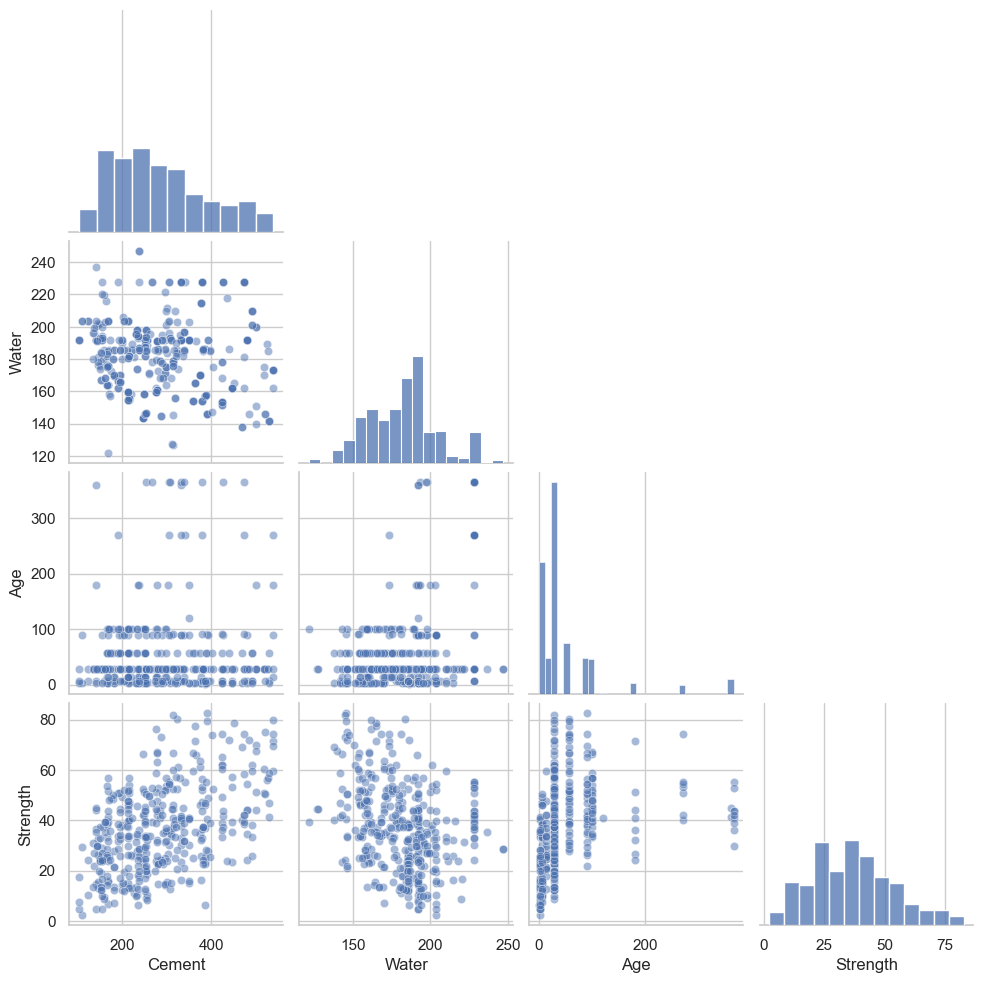

In [55]:
sns.pairplot(df[["Cement", "Water", "Age", "Strength"]].sample(400, random_state=RANDOM_STATE),
             corner=True, plot_kws={"alpha": 0.5})
plt.show()

**EDA takeaways**
- No missing values; duplicate rows were removed.
- Strength is moderately right-skewed (most samples 15-50 MPa).
- `Cement` and `Age` are positively related to strength; `Water` is negatively related (more water means weaker concrete).
- Relationships are not purely linear (e.g. strength grows quickly with early age then levels off), so non-linear models should help.

## 5. Experiment design
- **Task:** regression, target = `Strength` (MPa).
- **Split:** 80% train / 20% test, fixed seed. The test set is used once at the end.
- **Preprocessing:** `StandardScaler` inside a `Pipeline` (fit on training data only, to avoid leakage).
- **Models compared:** Linear Regression, Ridge, k-NN, Random Forest, Gradient Boosting.
- **Model selection:** 5-fold cross-validation on the training set (metric: RMSE, also R²).
- **Tuning:** `GridSearchCV` on the two best models.
- **Final evaluation:** RMSE, MAE and R² on the test set, plus residual analysis and feature importance.

## 6. Train/test split

In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    df[features], df["Strength"], test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (804, 8)  Test: (201, 8)


## 7. Baseline model comparison (cross-validation)

In [57]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "k-NN": KNeighborsRegressor(n_neighbors=5),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    pipe = Pipeline([("scale", StandardScaler()), ("reg", model)])
    rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2", n_jobs=-1)
    rows.append({"Model": name, "CV RMSE": rmse.mean(), "RMSE std": rmse.std(), "CV R2": r2.mean()})

results = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
results.round(3)

,Model,CV RMSE,RMSE std,CV R2
0,Gradient Boosting,5.296,0.400,0.889
1,Random Forest,5.345,0.481,0.886
2,k-NN,9.459,0.227,0.647
3,Ridge,10.202,0.152,0.590
4,Linear Regression,10.202,0.153,0.590


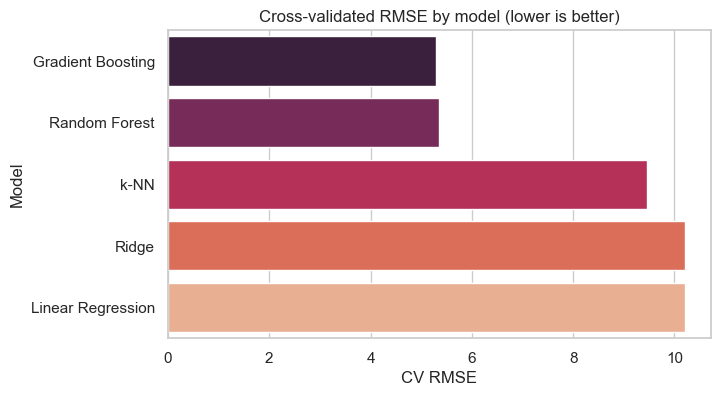

In [58]:
plt.figure(figsize=(7, 4))
sns.barplot(data=results, x="CV RMSE", y="Model", hue="Model", palette="rocket", legend=False)
plt.title("Cross-validated RMSE by model (lower is better)")
plt.show()

## 8. Hyperparameter tuning
Tune the Random Forest and Gradient Boosting models with a small grid (3-fold CV, RMSE).

In [59]:
rf_pipe = Pipeline([("scale", StandardScaler()),
                    ("reg", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
rf_grid = {"reg__n_estimators": [200, 400], "reg__max_depth": [None, 20], "reg__min_samples_leaf": [1, 2]}

gb_pipe = Pipeline([("scale", StandardScaler()),
                    ("reg", GradientBoostingRegressor(random_state=RANDOM_STATE))])
gb_grid = {"reg__n_estimators": [200, 400], "reg__learning_rate": [0.05, 0.1], "reg__max_depth": [3, 5]}

searches = {}
for name, pipe, grid in [("Random Forest", rf_pipe, rf_grid), ("Gradient Boosting", gb_pipe, gb_grid)]:
    gs = GridSearchCV(pipe, grid, cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name}: best CV RMSE = {-gs.best_score_:.3f} | params = {gs.best_params_}")

Random Forest: best CV RMSE = 5.521 | params = {'reg__max_depth': None, 'reg__min_samples_leaf': 1, 'reg__n_estimators': 200}
Gradient Boosting: best CV RMSE = 4.857 | params = {'reg__learning_rate': 0.1, 'reg__max_depth': 3, 'reg__n_estimators': 400}


## 9. Final evaluation on the test set

In [60]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
best_model = searches[best_name].best_estimator_
print("Selected model:", best_name)

# Compare with a simple linear baseline on the same test set
baseline = Pipeline([("scale", StandardScaler()), ("reg", LinearRegression())]).fit(X_train, y_train)

def report(model, label):
    pred = model.predict(X_test)
    return {"Model": label,
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "MAE": mean_absolute_error(y_test, pred),
            "R2": r2_score(y_test, pred)}

pd.DataFrame([report(baseline, "Linear Regression (baseline)"),
              report(best_model, f"{best_name} (tuned)")]).round(3)

Selected model: Gradient Boosting


,Model,RMSE,MAE,R2
0,Linear Regression (baseline),11.191,8.895,0.580
1,Gradient Boosting (tuned),4.440,3.068,0.934


### Predicted vs. actual (Chart 7)

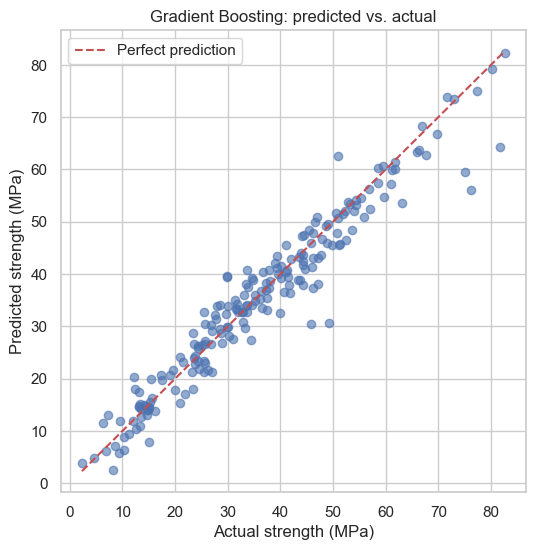

In [61]:
y_pred = best_model.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title(f"{best_name}: predicted vs. actual")
plt.legend()
plt.show()

### Residual analysis (Chart 8)

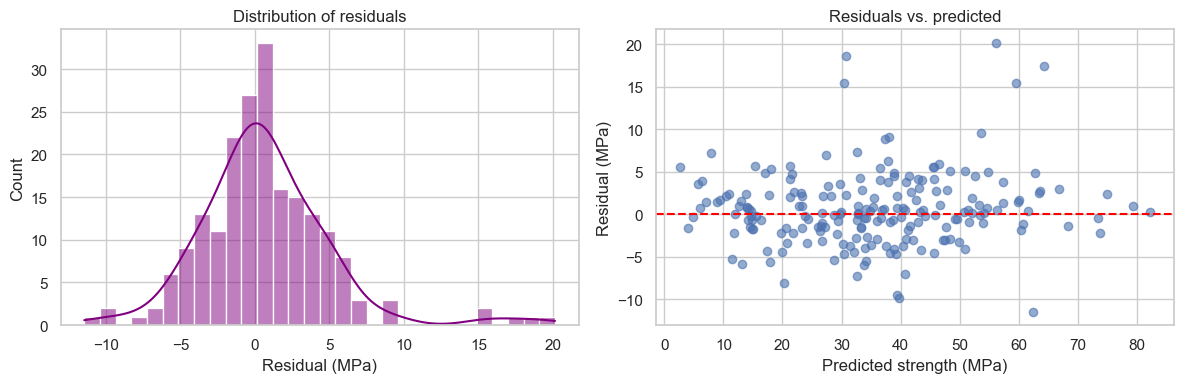

In [62]:
resid = y_test - y_pred
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(resid, bins=30, kde=True, ax=ax[0], color="purple")
ax[0].set_title("Distribution of residuals")
ax[0].set_xlabel("Residual (MPa)")
ax[1].scatter(y_pred, resid, alpha=0.6)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_title("Residuals vs. predicted")
ax[1].set_xlabel("Predicted strength (MPa)")
ax[1].set_ylabel("Residual (MPa)")
plt.tight_layout()
plt.show()

### Feature importance (Chart 9)
Permutation importance: how much the test R² drops when a feature is shuffled.

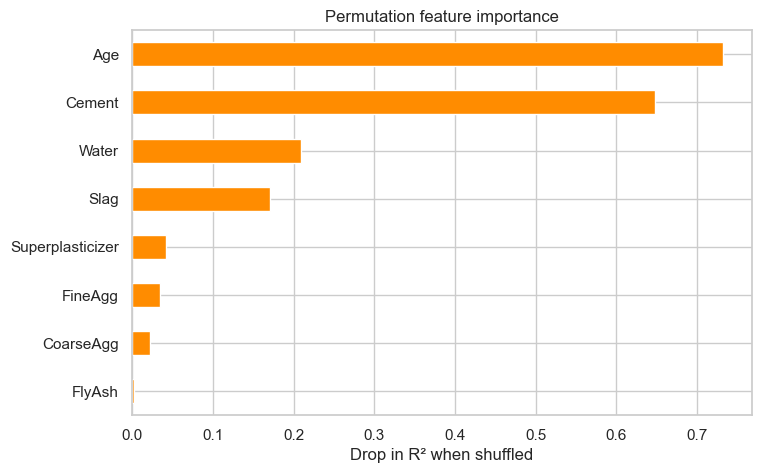

,importance
Age,0.7315
Cement,0.6482
Water,0.2087
Slag,0.1706
Superplasticizer,0.0425
FineAgg,0.0340
CoarseAgg,0.0223
FlyAsh,0.0025


In [63]:
perm = permutation_importance(best_model, X_test, y_test, scoring="r2",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=features).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="darkorange")
plt.xlabel("Drop in R² when shuffled")
plt.title("Permutation feature importance")
plt.show()
imp.sort_values(ascending=False).round(4).to_frame("importance")

## 10. Conclusion
- The tuned ensemble model clearly outperforms the linear baseline (see the test table in Section 9), confirming that the relationship between mix design and strength is non-linear.
- `Age` and `Cement` are the most influential inputs, with `Water` also important, which matches the EDA.
- Residuals are roughly centred at zero, with larger errors for very high-strength samples.

**Limitations:** only 1,030 lab samples, a single data source, and no information on material quality or curing conditions. The grid search was kept small to run quickly.

**Future work:** engineer features such as water-to-cement ratio or log(Age), try other models (e.g. XGBoost, neural networks), and validate on data from other labs.

## 11. References
- Yeh, I-C. (1998). *Cement and Concrete Research*, 28(12), 1797-1808.
- UCI Machine Learning Repository: Concrete Compressive Strength, https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength
- scikit-learn documentation, https://scikit-learn.org